# Reproducing the WVC 2026 paper

**Vegetation Encroachment Screening in Transmission-Line Rights-of-Way from Satellite Imagery**
(D. C. S. Braga, J. N. Gois, W. L. Passos, A. A. Lima, G. M. Araujo — PPEEL/CEFET-RJ)

This notebook regenerates **every table and figure** of the paper and **every number quoted in
the text**, section by section. A **checklist** at the end compares each number printed in the
paper with the value recomputed here.

### Images are not distributed

The images are crops of Google Maps imagery, whose terms do not allow bulk redistribution. This
repository ships the **labels**, the **split**, the **tower coordinates** and a **fingerprint of
every image** (`data/labels.csv`), plus the code to regenerate the images
(`docs/02_REGENERATING_THE_DATASET.md`). The notebook works in two modes:

| | without images (default) | with the regenerated dataset in `data/dataset/` |
|---|---|---|
| Tables I–III, Figs. 3, statistics, threshold sweep, geography, checklist | ✅ from the stored results | ✅ |
| Fig. 2 (examples) and Fig. 4 (errors), image-size check | — skipped | ✅ |
| Colour baseline recomputed from the pixels | — stored CSV used | ✅ |

Retraining the networks (hours of GPU) is not done here; see `docs/03_REPRODUCING_THE_PAPER.md`.

**Run:** `jupyter nbconvert --to notebook --execute --inplace notebooks/reproduce_paper.ipynb`.
Outputs go to `results/paper/`.

## 0. Setup

In [1]:
import os, sys, json
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
ROOT = Path.cwd()
assert (ROOT / "data" / "labels.csv").exists(), f"run from the repository (cwd={ROOT})"
for sub in ("training", "analysis", "figures", "dataset"):
    sys.path.insert(0, str(ROOT / "src" / sub))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import stats
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, confusion_matrix

DATA = ROOT / "data" / "dataset"
RES = ROOT / "results"
OUT = RES / "paper"
OUT.mkdir(parents=True, exist_ok=True)

LABELS = pd.read_csv(ROOT / "data" / "labels.csv")
LABELS["path"] = [DATA / s / l / f for s, l, f in zip(LABELS.split, LABELS.label, LABELS.file)]
HAVE_IMAGES = all(p.exists() for p in LABELS.path)
print("images found in data/dataset:", HAVE_IMAGES)

# ---- switches ---------------------------------------------------------------
RUN_COLOUR_BASELINE = HAVE_IMAGES   # recompute the colour baseline from the pixels (CPU, ~20 s)
# -----------------------------------------------------------------------------

CHECK = []
def check(section, number, paper, computed, tol):
    CHECK.append(dict(section=section, number=number, paper=paper,
                      computed=round(float(computed), 4), ok=abs(float(computed) - paper) <= tol))
    return computed

images found in data/dataset: False


### 0.1 Is the regenerated dataset the original one?

If you regenerated the images, `src/dataset/verify_dataset.py` compares them with the fingerprints
in `data/labels.csv` and writes `results/dataset_verification.csv`. Only images classified as
`IDENTICAL_FILE`/`IDENTICAL_PIXELS` reproduce the paper bit for bit. `SAME_SCENE` images show the
same place with small rendering differences.

In [2]:
ver = RES / "dataset_verification.csv"
if ver.exists():
    v = pd.read_csv(ver)
    display(v.status.value_counts().to_frame("images"))
else:
    print("no verification report (images not regenerated) -> working from the stored results")

no verification report (images not regenerated) -> working from the stored results


## 1. Section III — Dataset construction

### 1.1 Extraction pipeline (Fig. 1 and Algorithm 1)

Fig. 1 (flowchart) and Algorithm 1 are typeset in LaTeX in the paper; no code draws them. The
pipeline is implemented by `src/extraction/extrator_imagens.py` (the original extractor) and
`src/extraction/regenerate_images_qgis.py` (regeneration of exactly the 351 towers), both run in
the QGIS Python console. The cell below reproduces steps 2–4 for one image without QGIS: the number
at the start of the file name is the row of the EPE tower spreadsheet.

In [3]:
towers = pd.read_excel(ROOT / "data/metadata/coordenadas_extraidas.xlsx")
print(f"towers (vertices) of the Basic Network: {len(towers):,}")
check("III", "tower coordinates extracted in QGIS", 194299, len(towers), 0)

IMAGE_PX, RESOLUTION = 650, 0.25            # extrator_imagens.py
L = IMAGE_PX * RESOLUTION                   # 162.5 m
check("III-D", "ground coverage (m)", 162.5, L, 0)

from pyproj import Transformer
to_3857 = Transformer.from_crs("EPSG:4674", "EPSG:3857", always_xy=True)
r = towers.iloc[44620]
x, y = to_3857.transform(r.X_coord_pre, r.Y_coord_pre)
print(f"\n44620_G1_800.png -> {r.Nome} ({r.Tensao} kV)")
print(f"  EPSG:4674  lon={r.X_coord_pre:.6f}  lat={r.Y_coord_pre:.6f}")
print(f"  EPSG:3857  x={x:,.1f}  y={y:,.1f}")
print(f"  extent     [{x-L/2:,.1f}, {x+L/2:,.1f}] x [{y-L/2:,.1f}, {y+L/2:,.1f}]  ({L} m side)")

towers (vertices) of the Basic Network: 194,299

44620_G1_800.png -> LT 800 kV CC Xingu - Estreito, C1 (800 kV)
  EPSG:4674  lon=-49.705482  lat=-6.074573
  EPSG:3857  x=-5,533,188.9  y=-677,488.8
  extent     [-5,533,270.2, -5,533,107.7] x [-677,570.0, -677,407.5]  (162.5 m side)


### 1.2 Table I — voltage groups

Table I describes the **sampling** (100 towers per group). Groups as defined in the extractor:
G1 = 800 kV; G2 = 765, 600 kV; G3 = 500, 440, 345 kV; G4 = 230, 138 kV.

> ⚠️ **Note.** The Basic Network spreadsheet has **no 138 kV tower**, so the sampled G4 is 100 %
> 230 kV. Towers at 525 kV (12,624) and 132 kV (33) belong to no group. The last row shows what was
> actually sampled.

In [4]:
sampled = {g: pd.read_excel(ROOT / f"data/metadata/coordenadas_sorteadas/{g}_sorteadas.xlsx") for g in ["G1", "G2", "G3", "G4"]}
DEFINITION = {"G1": [800], "G2": [765, 600], "G3": [500, 440, 345], "G4": [230, 138]}
tab1 = pd.DataFrame({g: {"Voltage (kV)": ",".join(map(str, DEFINITION[g])), "Number of images": len(d),
                         "(sampled kV: count)": ", ".join(f"{v}: {c}" for v, c in d.Tensao.value_counts().sort_index(ascending=False).items())}
                     for g, d in sampled.items()})
tab1.index.name = "Characteristics"
display(tab1)
tab1.to_csv(OUT / "table1_groups.csv"); tab1.to_latex(OUT / "table1_groups.tex")
for g in sampled:
    check("Tab. I", f"sampled images {g}", 100, len(sampled[g]), 0)
print("towers per voltage in the spreadsheet:", towers.Tensao.value_counts().sort_index().to_dict())
print("\nimages kept after curation, per group and class:")
display(pd.crosstab(LABELS.group, LABELS.label, margins=True, margins_name="total"))

,G1,G2,G3,G4
Characteristics,,,,
Voltage (kV),800,"765,600","500,440,345","230,138"
Number of images,100,100,100,100
(sampled kV: count),800: 100,"765: 40, 600: 60","500: 67, 440: 6, 345: 27",230: 100


towers per voltage in the spreadsheet: {132: 33, 230: 89609, 345: 18646, 440: 5534, 500: 49746, 525: 12624, 600: 10917, 765: 5652, 800: 1538}

images kept after curation, per group and class:


label,NOK,OK,total
group,,,
G1,23,67,90
G2,34,64,98
G3,25,70,95
G4,19,49,68
total,101,250,351


### 1.3 Curation and train / validation / test split (Section III-D)

400 images were extracted; those with very poor quality or no visible tower were discarded. The
remaining 351 were split at random 60/20/20 %. The split is given by the `split` column of
`data/labels.csv`, which must not be changed: every number in the paper depends on it.

In [5]:
split = pd.crosstab(LABELS.split, LABELS.label).reindex(["train", "val", "test"])[["OK", "NOK"]]
split["total"] = split.sum(axis=1)
split["%"] = 100 * split.total / split.total.sum()
display(split)
split.to_csv(OUT / "dataset_split.csv")
n = len(LABELS)
check("III-D", "images after curation", 351, n, 0)
check("III-D", "discarded images", 49, 400 - n, 0)
check("III-D", "% discarded (49/400 = 12.25)", 12.2, 100 * (400 - n) / 400, 0.051)
for s, (ok, nok) in {"train": (146, 64), "val": (53, 19), "test": (51, 18)}.items():
    check("III-D", f"{s} OK", ok, split.loc[s, "OK"], 0)
    check("III-D", f"{s} NOK", nok, split.loc[s, "NOK"], 0)
if HAVE_IMAGES:
    sizes = {Image.open(p).size for p in LABELS.path}
    print("image sizes found:", sizes); assert sizes == {(650, 650)}

label,OK,NOK,total,%
split,,,,
train,146,64,210,59.829060
val,53,19,72,20.512821
test,51,18,69,19.658120


### 1.4 Fig. 2 — dataset examples (one per group). *Imagery © Google.* Requires the images.

In [6]:
examples = ["44620_G1_800.png", "27304_G2_765.png", "48136_G3_500.png", "72811_G4_230.png"]
if HAVE_IMAGES:
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
    for ax, name in zip(axes, examples):
        row = LABELS[LABELS.file == name].iloc[0]
        ax.imshow(Image.open(row.path).convert("RGB")); ax.axis("off")
        ax.set_title(f"Group {row.group} — {row.voltage_kv} kV\n({row.split}, {row.label})", fontsize=9)
    fig.suptitle("Fig. 2 — Examples from the dataset, one per voltage group. Imagery © Google.", fontsize=10)
    fig.tight_layout(); fig.savefig(OUT / "fig2_dataset_examples.png", dpi=200); plt.show()
else:
    print("skipped (no images). Fig. 2 uses:", ", ".join(examples))

skipped (no images). Fig. 2 uses: 44620_G1_800.png, 27304_G2_765.png, 48136_G3_500.png, 72811_G4_230.png


### 1.5 Geographic coverage and leakage between splits (Sections III-D and V-E)

The line name and coordinate of every image come from the EPE spreadsheet (columns `line_name`,
`lon`, `lat` of `labels.csv`). Same logic as `src/analysis/analise_geografica.py`.

distinct transmission lines: 170;  latitude from 0.7° S to 31.7° S
test : 17/69 images (25 %) on a line also present in training
val  : 49/72 images (68 %) on a line also present in training
test -> nearest training image: median 30.5 km, min 22 m; < 1 km: 1/69


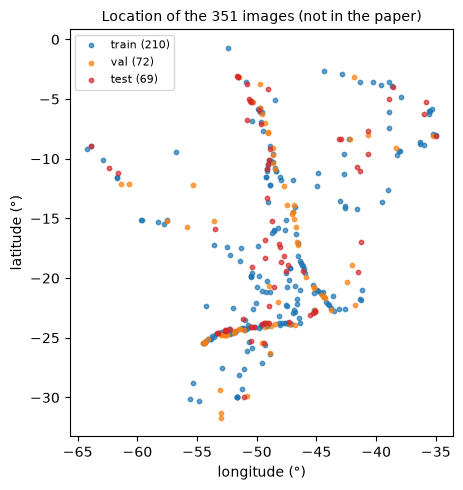

,test NOK
group,
G1,2
G2,4
G3,9
G4,3


2

In [7]:
geo = LABELS.copy()
n_lines = geo.line_name.nunique()
print(f"distinct transmission lines: {n_lines};  latitude from {-geo.lat.max():.1f}° S to {-geo.lat.min():.1f}° S")
check("III-D", "distinct lines", 170, n_lines, 0)
check("III-D", "northernmost latitude (°S)", 0.7, -geo.lat.max(), 0.05)
check("III-D", "southernmost latitude (°S)", 31.7, -geo.lat.min(), 0.05)

train_lines = set(geo[geo.split == "train"].line_name)
for s, ref in [("test", 25), ("val", 68)]:
    sub = geo[geo.split == s]
    frac = 100 * sub.line_name.isin(train_lines).mean()
    print(f"{s:5s}: {sub.line_name.isin(train_lines).sum()}/{len(sub)} images ({frac:.0f} %) on a line also present in training")
    check("V-A / V-E", f"% {s} sharing a line with train", ref, frac, 0.5)

def haversine_km(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

tr, te = geo[geo.split == "train"], geo[geo.split == "test"]
dist = np.array([haversine_km(r.lat, r.lon, tr.lat.values, tr.lon.values).min() for r in te.itertuples()])
print(f"test -> nearest training image: median {np.median(dist):.1f} km, min {dist.min()*1000:.0f} m; < 1 km: {(dist < 1).sum()}/{len(dist)}")
check("V-E", "median test-train distance (km)", 30.5, np.median(dist), 0.05)
check("V-E", "test images < 1 km from training", 1, (dist < 1).sum(), 0)

fig, ax = plt.subplots(figsize=(5, 5))
for s, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:red")]:
    g = geo[geo.split == s]; ax.scatter(g.lon, g.lat, s=10, c=c, label=f"{s} ({len(g)})", alpha=0.7)
ax.set_xlabel("longitude (°)"); ax.set_ylabel("latitude (°)"); ax.set_aspect("equal"); ax.legend(fontsize=8)
ax.set_title("Location of the 351 images (not in the paper)", fontsize=10)
fig.tight_layout(); fig.savefig(OUT / "extra_map.png", dpi=200); plt.show()

nok_test = LABELS[(LABELS.split == "test") & (LABELS.label == "NOK")].group.value_counts().sort_index()
display(nok_test.to_frame("test NOK"))
check("V-E", "test NOK in G3", 9, nok_test.get("G3", 0), 0)
check("V-E", "test NOK in G1", 2, nok_test.get("G1", 0), 0)

### 1.6 Footprint overlap between images (Section V-E)

Each image covers a 162.5 m square **in Web Mercator units**. The common area fraction is computed
for every pair, as in `src/analysis/analise_sobreposicao.py`.

In [8]:
R_EARTH = 6378137.0
mx = np.radians(geo.lon.values) * R_EARTH
my = R_EARTH * np.log(np.tan(np.pi / 4 + np.radians(geo.lat.values) / 2))
dx = np.abs(mx[:, None] - mx[None, :]); dy = np.abs(my[:, None] - my[None, :])
overlap = np.clip(L - dx, 0, L) * np.clip(L - dy, 0, L) / L**2
np.fill_diagonal(overlap, 0)
iu = np.triu_indices(len(geo), 1)
pairs = list(zip(*np.where(np.triu(overlap, 1) > 0)))
print(f"pairs: {len(iu[0]):,}   overlapping pairs: {len(pairs)}   images involved: {(overlap.max(axis=1) > 0).sum()}")
check("V-E", "pairs evaluated", 61425, len(iu[0]), 0)
check("V-E", "overlapping pairs", 7, len(pairs), 0)

G = geo.reset_index(drop=True)
tab_ov = pd.DataFrame([dict(img1=f"{G.split[i]}/{G.label[i]}/{G.tower_index[i]}", img2=f"{G.split[j]}/{G.label[j]}/{G.tower_index[j]}",
                            overlap_pct=100 * overlap[i, j], distance_m=np.hypot(mx[i] - mx[j], my[i] - my[j]),
                            same_line=G.line_name[i] == G.line_name[j], line1=G.line_name[i], line2=G.line_name[j]) for i, j in pairs])
display(tab_ov)
cross = tab_ov[tab_ov.img1.str.split("/").str[0] != tab_ov.img2.str.split("/").str[0]]
check("V-E", "pairs crossing train/test", 1, len(cross), 0)
pair = cross.iloc[0]
leaked = next(im for im in (pair.img1, pair.img2) if im.startswith("test/")).split("/")[-1]
print("test image with an overlapping training neighbour:", leaked)

sc = np.load(RES / "nok_analysis" / "scores_test.npz")
y_te = sc["y"]
mask = np.array([leaked not in str(p) for p in sc["paths"]])
for m in ("resnet", "yolo"):
    s = sc[m]
    f_all, f_wo = 100 * f1_score(y_te, s >= 0.5, average="macro"), 100 * f1_score(y_te[mask], s[mask] >= 0.5, average="macro")
    a_all, a_wo = roc_auc_score(y_te, s), roc_auc_score(y_te[mask], s[mask])
    print(f"{m:6s} macro-F1 {f_all:.1f} -> {f_wo:.1f} (Δ {f_all - f_wo:.1f})   ROC-AUC {a_all:.3f} -> {a_wo:.3f} (Δ {a_all - a_wo:.3f})")
    check("V-E", f"Δ macro-F1 without the overlapping image ({m})", 0.6, f_all - f_wo, 0.05)
    check("V-E", f"Δ ROC-AUC without the overlapping image ({m})", 0.002, a_all - a_wo, 0.0005)

pairs: 61,425   overlapping pairs: 7   images involved: 6


,img1,img2,overlap_pct,distance_m,same_line,line1,line2
0,train/NOK/44685,test/NOK/172788,83.457213,22.366834,False,"LT 800 kV CC Xingu - Estreito, C1","LT 800 kV CC Xingu - Estreito, C2"
1,train/OK/57854,train/OK/57896,97.996105,2.410513,True,"LT 230 kV Santa Cruz 1 - Charqueadas 3, C1","LT 230 kV Santa Cruz 1 - Charqueadas 3, C1"
2,train/OK/57854,train/OK/58281,84.678786,20.570812,True,"LT 230 kV Santa Cruz 1 - Charqueadas 3, C1","LT 230 kV Santa Cruz 1 - Charqueadas 3, C1"
3,train/OK/57854,train/OK/91598,69.541025,38.308520,False,"LT 230 kV Santa Cruz 1 - Charqueadas 3, C1","LT 230 kV Cidade Industrial - Charqueadas 3, C1"
4,train/OK/57896,train/OK/58281,86.567587,18.219563,True,"LT 230 kV Santa Cruz 1 - Charqueadas 3, C1","LT 230 kV Santa Cruz 1 - Charqueadas 3, C1"
5,train/OK/57896,train/OK/91598,69.991835,37.928419,False,"LT 230 kV Santa Cruz 1 - Charqueadas 3, C1","LT 230 kV Cidade Industrial - Charqueadas 3, C1"
6,train/OK/58281,train/OK/91598,75.929047,35.767032,False,"LT 230 kV Santa Cruz 1 - Charqueadas 3, C1","LT 230 kV Cidade Industrial - Charqueadas 3, C1"


test image with an overlapping training neighbour: 172788
resnet macro-F1 86.6 -> 86.0 (Δ 0.6)   ROC-AUC 0.935 -> 0.933 (Δ 0.002)
yolo   macro-F1 88.3 -> 87.7 (Δ 0.6)   ROC-AUC 0.943 -> 0.941 (Δ 0.002)


## 2. Section IV — Classification system

### 2.1 Bootstrap protocol

Each model was retrained 30 times; at each replicate the 210 training images are resampled **with
replacement, stratified per class**, with validation and test fixed. Seeds: 1000+i (ResNet18),
2000+i (YOLO26), 3000+i (colour baseline). The paper states that each resample contains **about
63 % distinct images** (expected value 1 − 1/e); checked below on the actual resamples, which only
depend on the file lists of `labels.csv`.

In [9]:
from bootstrap_common import CLASSES, bootstrap_resample
train_files = {c: sorted(p for p in LABELS.path[(LABELS.split == "train") & (LABELS.label == c)]) for c in CLASSES}
distinct = [len({p for ps in bootstrap_resample(train_files, seed=1000 + i).values() for p in ps}) / 210 for i in range(30)]
print(f"distinct images per resample: {100*np.mean(distinct):.1f} % (theory {100*(1-np.exp(-1)):.1f} %)")
check("IV", "% distinct images per resample", 63, 100 * np.mean(distinct), 1.0)

distinct images per resample: 63.9 % (theory 63.2 %)


63.92063492063493

### 2.2 YOLO26 optimizer ablation (Section IV)

Single runs of 7 configurations (`src/training/yolo_ablation.py`), then full bootstraps of the
candidates. The paper uses `explicit_adamw` (AdamW, lr 1e-4, cosine). This screening looked at the
test set, which the paper lists as a limitation.

In [10]:
abl = pd.read_csv(RES / "yolo_ablation" / "results.csv").set_index("config")
display(abl[["val_macro_f1", "test_macro_f1", "test_NOK_recall"]].round(2))
boot = lambda name: pd.read_csv(RES / name / "results.csv")
B = {"ResNet18": boot("bootstrap_resnet"), "YOLO26 (AdamW) — paper": boot("bootstrap_yolo_adamw"),
     "YOLO26 (optimizer=auto)": boot("bootstrap_yolo_auto"), "YOLO26-nano + light aug + AdamW": boot("bootstrap_yolo_nano")}
tb = pd.DataFrame({k: {"test macro-F1 mean": v.test_macro_f1.mean(), "std (ddof=1)": v.test_macro_f1.std(ddof=1),
                       "Welch p vs ResNet18": stats.ttest_ind(B["ResNet18"].test_macro_f1, v.test_macro_f1, equal_var=False).pvalue}
                   for k, v in B.items()}).T
display(tb.round(3)); tb.to_csv(OUT / "extra_yolo_ablation_bootstrap.csv")

,val_macro_f1,test_macro_f1,test_NOK_recall
config,,,
baseline_current,89.92,78.95,66.67
light_aug,89.62,82.77,72.22
explicit_adamw,89.92,88.29,77.78
light_aug_adamw,91.48,85.44,66.67
light_aug_adamw_dropout,89.92,87.79,72.22
light_aug_adamw_imgsz224,91.21,81.28,61.11
light_aug_adamw_nano,89.92,88.73,83.33


,test macro-F1 mean,std (ddof=1),Welch p vs ResNet18
ResNet18,83.125,4.188,1.000
YOLO26 (AdamW) — paper,81.817,5.023,0.278
YOLO26 (optimizer=auto),78.867,4.572,0.000
YOLO26-nano + light aug + AdamW,80.082,4.258,0.007


## 3. Sections V-A/B — Validation and test results

### 3.1 Validation (also the early-stopping criterion, hence optimistic)

In [11]:
res, yol = B["ResNet18"], B["YOLO26 (AdamW) — paper"]
for name, d, ref_m, ref_s in [("ResNet18", res, 91.6, 2.0), ("YOLO26", yol, 90.7, 2.1)]:
    m, s = d.val_macro_f1.mean(), d.val_macro_f1.std(ddof=1)
    print(f"{name:9s} val macro-F1 = {m:.1f} % ± {s:.1f}  |  val -> test gap = {m - d.test_macro_f1.mean():.1f} points")
    check("V-A", f"val macro-F1 {name}", ref_m, m, 0.05)
    check("V-A", f"val macro-F1 std {name}", ref_s, s, 0.05)
check("V-A", "val->test gap (ResNet18)", 8.5, res.val_macro_f1.mean() - res.test_macro_f1.mean(), 0.05)

ResNet18  val macro-F1 = 91.6 % ± 2.0  |  val -> test gap = 8.5 points
YOLO26    val macro-F1 = 90.7 % ± 2.1  |  val -> test gap = 8.8 points


8.514679999999984

### 3.2 Colour baseline

Six colour statistics per image (ExG mean, std and green fraction; CIELAB a\* mean and green
fraction; mean green ratio) fed to a logistic regression, same bootstrap protocol
(`src/training/color_baseline.py`). Recomputed from the pixels when the images are present;
otherwise the stored per-replicate results are used.

In [12]:
if RUN_COLOUR_BASELINE:
    import color_baseline
    color_baseline.main()
cor = pd.read_csv(RES / "color_baseline" / "logreg_bootstrap.csv")
cor_sum = json.loads((RES / "color_baseline" / "summary.json").read_text())
display(pd.DataFrame(cor_sum["ranking"]).set_index("name").round(3))

,ap,roc_auc
name,,
exg_mean,0.298,0.583
exg_frac,0.313,0.621
lab_a_mean,0.310,0.612
green_ratio,0.354,0.577
logreg,0.437,0.772


### 3.3 Table II — test metrics (mean ± std over 30 replicates)

> ⚠️ **Known inconsistency in the printed paper (≤ 0.2 point).** In Table II, the **per-class**
> rows of ResNet18 and YOLO26 use the **population** std (ddof = 0), while their macro-F1 row and the
> whole Colour column use the **sample** std (ddof = 1). Both versions are produced below; the
> checklist verifies the table **as printed**.

In [13]:
rows = [("OK recall", "OK_recall"), ("OK precision", "OK_precision"), ("OK F1", "OK_f1"), ("NOK recall", "NOK_recall"),
        ("NOK precision", "NOK_precision"), ("NOK F1", "NOK_f1"), ("macro F1", "macro_f1")]
sources = {"Colour": (cor, ""), "ResNet18": (res, "test_"), "YOLO26": (yol, "test_")}
printed_ddof = lambda model, col: 0 if (model != "Colour" and col != "macro_f1") else 1

def table2(ddof_of):
    t = pd.DataFrame({m: {lab: f"{d[p+c].mean():.1f}±{d[p+c].std(ddof=ddof_of(m, c)):.1f}" for lab, c in rows} for m, (d, p) in sources.items()})
    t.index.name = "metric (%)"; return t

tab2, tab2_consistent = table2(printed_ddof), table2(lambda m, c: 1)
print("Table II as printed:"); display(tab2)
print("Table II, consistent (all ddof=1):"); display(tab2_consistent)
tab2.to_csv(OUT / "table2_test.csv"); tab2.to_latex(OUT / "table2_test.tex")
tab2_consistent.to_csv(OUT / "table2_test_ddof1.csv"); tab2_consistent.to_latex(OUT / "table2_test_ddof1.tex")

paper_t2 = {"Colour":   [(62.0, 4.6), (90.2, 2.3), (73.3, 3.0), (80.7, 5.6), (43.0, 2.5), (56.0, 2.5), (64.7, 2.5)],
            "ResNet18": [(91.4, 6.3), (91.4, 3.3), (91.2, 2.8), (74.8, 11.1), (77.7, 10.2), (75.1, 6.0), (83.1, 4.2)],
            "YOLO26":   [(92.4, 4.7), (89.9, 3.7), (91.0, 2.4), (70.0, 12.8), (77.9, 9.2), (72.6, 7.9), (81.8, 5.0)]}
for m, refs in paper_t2.items():
    d, p = sources[m]
    for (lab, c), (rm, rs) in zip(rows, refs):
        dd = printed_ddof(m, c)
        check("Tab. II", f"{m} {lab} mean", rm, d[p + c].mean(), 0.051)
        check("Tab. II", f"{m} {lab} std (ddof={dd})", rs, d[p + c].std(ddof=dd), 0.051)

Table II as printed:


,Colour,ResNet18,YOLO26
metric (%),,,
OK recall,62.0±4.6,91.4±6.3,92.4±4.7
OK precision,90.2±2.3,91.4±3.3,89.9±3.7
OK F1,73.3±3.0,91.2±2.8,91.0±2.4
NOK recall,80.7±5.6,74.8±11.1,70.0±12.8
NOK precision,43.0±2.5,77.7±10.2,77.9±9.2
NOK F1,56.0±2.5,75.1±5.9,72.6±7.9
macro F1,64.7±2.5,83.1±4.2,81.8±5.0


Table II, consistent (all ddof=1):


,Colour,ResNet18,YOLO26
metric (%),,,
OK recall,62.0±4.6,91.4±6.4,92.4±4.8
OK precision,90.2±2.3,91.4±3.3,89.9±3.7
OK F1,73.3±3.0,91.2±2.9,91.0±2.4
NOK recall,80.7±5.6,74.8±11.3,70.0±13.0
NOK precision,43.0±2.5,77.7±10.3,77.9±9.4
NOK F1,56.0±2.5,75.1±6.1,72.6±8.1
macro F1,64.7±2.5,83.1±4.2,81.8±5.0


### 3.4 ResNet18 vs YOLO26 — Welch's t-test and CI of the difference

Replicates are independent (different resamples), hence the unpaired Welch test; the 95 % CI of the
difference uses Welch–Satterthwaite degrees of freedom. A high p-value is **not** evidence of
equivalence; the CI shows which differences the experiment can rule out.

ResNet18 - YOLO26 = 1.31 points   t = 1.095   dof = 56.2   p = 0.2781   95 % CI = [-1.08, 3.70]


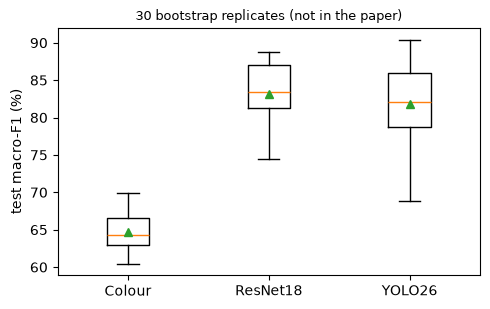

In [14]:
a, b = res.test_macro_f1.values, yol.test_macro_f1.values
t, p = stats.ttest_ind(a, b, equal_var=False)
va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
dof = (va + vb) ** 2 / (va**2 / (len(a) - 1) + vb**2 / (len(b) - 1))
diff, half = a.mean() - b.mean(), stats.t.ppf(0.975, dof) * np.sqrt(va + vb)
print(f"ResNet18 - YOLO26 = {diff:.2f} points   t = {t:.3f}   dof = {dof:.1f}   p = {p:.4f}   95 % CI = [{diff-half:.2f}, {diff+half:.2f}]")
check("V-B", "macro-F1 difference (points)", 1.3, diff, 0.05)
check("V-B", "p (Welch)", 0.28, p, 0.005)
check("V-B", "95 % CI lower", -1.1, diff - half, 0.05)
check("V-B", "95 % CI upper", 3.7, diff + half, 0.05)

auc = {r["name"]: r["roc_auc"] for r in cor_sum["ranking"]}
singles = [auc[k] for k in ("exg_mean", "exg_frac", "lab_a_mean", "green_ratio")]
check("V-B", "colour baseline ROC-AUC (logreg)", 0.772, auc["logreg"], 0.0005)
check("V-B", "single colour index ROC-AUC (min)", 0.58, min(singles), 0.005)
check("V-B", "single colour index ROC-AUC (max)", 0.62, max(singles), 0.005)
check("V-B", "macro-F1 points added by the networks", 18, (a.mean() + b.mean()) / 2 - cor.macro_f1.mean(), 1.0)

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.boxplot([cor.macro_f1, a, b], tick_labels=["Colour", "ResNet18", "YOLO26"], showmeans=True)
ax.set_ylabel("test macro-F1 (%)"); ax.set_title("30 bootstrap replicates (not in the paper)", fontsize=9)
fig.tight_layout(); fig.savefig(OUT / "extra_bootstrap_boxplot.png", dpi=200); plt.show()

## 4. Section V-C — Operating point and error analysis

The threshold analysis uses **one representative training run of each model** (ResNet18:
`train_baseline.py`, seed 42; YOLO26: ablation config `explicit_adamw`, seed 42). Their P(NOK) on
the 69 test images are stored in `results/nok_analysis/scores_test.npz` (no pixels in it). The
bootstrap runs did not keep per-image scores, which is why this analysis has no error bars (a
limitation stated in the paper).

In [15]:
s_res, s_yol = sc["resnet"], sc["yolo"]
prev = y_te.mean()
print(f"test: {len(y_te)} images, {y_te.sum()} NOK -> prevalence {prev:.2f}; recall step 1/18 = {100/18:.1f} pp")
check("V-C", "NOK prevalence on test", 0.26, prev, 0.005)
for name, s, ap_ref, auc_ref, prec_ref in [("ResNet18", s_res, 0.842, 0.935, 82.4), ("YOLO26", s_yol, 0.863, 0.943, 87.5)]:
    ap, au = average_precision_score(y_te, s), roc_auc_score(y_te, s)
    pred = s >= 0.5; tp = int((pred & (y_te == 1)).sum()); fp = int((pred & (y_te == 0)).sum())
    print(f"{name:9s} AP = {ap:.3f}  ROC-AUC = {au:.3f}  | threshold 0.5: {tp}/18 NOK recovered, NOK precision {100*tp/(tp+fp):.1f} %")
    check("V-C", f"AP {name}", ap_ref, ap, 0.0005)
    check("V-C", f"ROC-AUC {name}", auc_ref, au, 0.0005)
    check("V-C", f"NOK recovered at 0.5 ({name})", 14, tp, 0)
    check("V-C", f"NOK precision at 0.5 ({name}, %)", prec_ref, 100 * tp / (tp + fp), 0.05)
    check("V-C", f"NOK recall at 0.5 ({name}, %)", 77.8, 100 * tp / 18, 0.05)

test: 69 images, 18 NOK -> prevalence 0.26; recall step 1/18 = 5.6 pp
ResNet18  AP = 0.842  ROC-AUC = 0.935  | threshold 0.5: 14/18 NOK recovered, NOK precision 82.4 %
YOLO26    AP = 0.863  ROC-AUC = 0.943  | threshold 0.5: 14/18 NOK recovered, NOK precision 87.5 %


### 4.2 Fig. 3 — NOK precision–recall curve (same function as `src/figures/refazer_figuras_wvc.py`, final size)

  pr_curve_nok.png


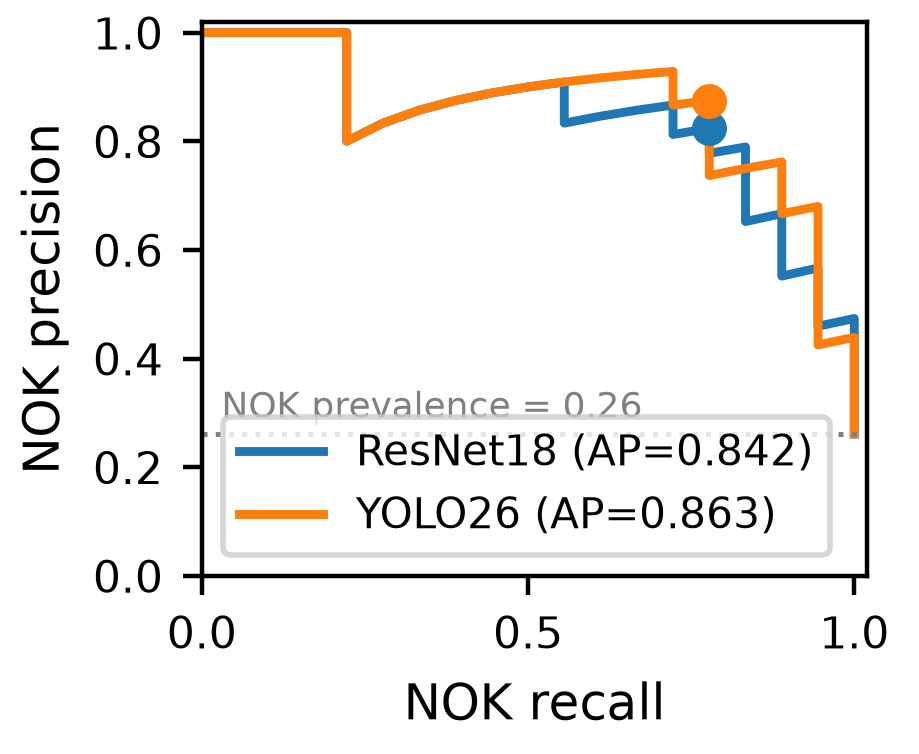

In [16]:
import refazer_figuras_wvc as rf
rf.OUT = OUT
rf.curva_pr(np.load(RES / "nok_analysis" / "scores_test.npz"))
(OUT / "pr_curve_nok.png").replace(OUT / "fig3_pr_curve_nok.png")
display(Image.open(OUT / "fig3_pr_curve_nok.png"))

### 4.3 Threshold sweep — inspection cost

NOK is the positive class; predict NOK when P(NOK) ≥ t. *Inspections* = segments sent to the field
(TP + FP); *missed* = undetected NOK (FN). The sweep is run **on the test set itself**: it
characterizes the available operating curve, not a deployment threshold.

In [17]:
# same rule as sweep_table() in src/analysis/nok_analysis.py, which imports torch/ultralytics
def sweep_table(y, s):
    rows = []
    for t in sorted(set(np.round(s, 4)), reverse=True):
        pred = s >= t; tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum())
        rows.append(dict(threshold=t, inspections=tp + fp, missed=int(y.sum()) - tp))
    return pd.DataFrame(rows)
cost = pd.DataFrame({name: sweep_table(y_te, s).groupby("missed").inspections.min() for name, s in [("ResNet18", s_res), ("YOLO26", s_yol)]}).loc[0:5]
cost.index.name = "NOK missed (of 18)"
for name in ("ResNet18", "YOLO26"):
    cost[f"spared {name} (%)"] = 100 * (69 - cost[name]) / 69
display(cost.round(1)); cost.to_csv(OUT / "threshold_sweep_inspections.csv")
check("V-C", "inspections for 100 % recall (ResNet18)", 39, cost.loc[0, "ResNet18"], 0)
check("V-C", "inspections for 100 % recall (YOLO26)", 41, cost.loc[0, "YOLO26"], 0)
check("V-C", "inspections for 1 missed (ResNet18)", 30, cost.loc[1, "ResNet18"], 0)
check("V-C", "inspections for 1 missed (YOLO26)", 25, cost.loc[1, "YOLO26"], 0)
check("abstract", "% spared at 100 % recall (~40 %, ResNet18)", 40, cost.loc[0, "spared ResNet18 (%)"], 3.5)
check("abstract", "% spared at 100 % recall (~40 %, YOLO26)", 40, cost.loc[0, "spared YOLO26 (%)"], 3.5)

# the stored sweep CSVs (src/analysis/nok_analysis.py) give the same minima
for name, f in [("ResNet18", "sweep_resnet18.csv"), ("YOLO26", "sweep_yolo26.csv")]:
    sw = pd.read_csv(RES / "nok_analysis" / f)
    assert sw.groupby("nok_perdidos").inspecoes.min().loc[0:5].tolist() == cost[name].tolist()

,ResNet18,YOLO26,spared ResNet18 (%),spared YOLO26 (%)
NOK missed (of 18),,,,
0,39.0,41.0,43.5,40.6
1,30.0,25.0,56.5,63.8
2,25.0,21.0,63.8,69.6
3,20.0,20.0,71.0,71.0
4,17.0,16.0,75.4,76.8
5,16.0,14.0,76.8,79.7


### 4.4 Agreement between the models and relation with colour

In [18]:
agree = 100 * ((s_res >= 0.5) == (s_yol >= 0.5)).mean()
corr = np.corrcoef(s_res, s_yol)[0, 1]
print(f"identical predictions: {agree:.1f} %   Pearson correlation of scores: {corr:.2f}")
check("V-C", "% identical predictions", 89.9, agree, 0.05)
check("V-C", "correlation between scores", 0.85, corr, 0.005)
ft = np.load(RES / "color_baseline" / "features_test.npz")
pos = {Path(str(p)).name: k for k, p in enumerate(sc["paths"])}
perm = [pos[Path(str(p)).name] for p in ft["paths"]]
exg = ft["X"][:, list(ft["features"]).index("exg_mean")]
for name, s, ref in [("ResNet18", s_res, 0.17), ("YOLO26", s_yol, 0.14)]:
    c = np.corrcoef(exg, s[perm])[0, 1]
    print(f"correlation mean ExG x {name}: {c:.2f}")
    check("V-C", f"colour x {name} correlation", ref, c, 0.005)

identical predictions: 89.9 %   Pearson correlation of scores: 0.85
correlation mean ExG x ResNet18: 0.17
correlation mean ExG x YOLO26: 0.14


### 4.5 Fig. 4 — characteristic errors (the figure requires the images; the table does not)

In [19]:
err = pd.DataFrame({"file": [Path(str(p)).name for p in sc["paths"]], "true": np.where(y_te == 1, "NOK", "OK"),
                    "P(NOK) ResNet18": s_res, "P(NOK) YOLO26": s_yol})
err["ResNet18 wrong"] = (s_res >= 0.5) != (y_te == 1)
err["YOLO26 wrong"] = (s_yol >= 0.5) != (y_te == 1)
display(err[err["ResNet18 wrong"] | err["YOLO26 wrong"]].sort_values("true").round(2))
fp_high = err.set_index("file").loc["179391_G4_230.png"]
check("V-C", "P(NOK) of the bottom-left FP, ResNet18", 1.00, fp_high["P(NOK) ResNet18"], 0.005)
check("V-C", "P(NOK) of the bottom-left FP, YOLO26", 0.96, fp_high["P(NOK) YOLO26"], 0.005)
if HAVE_IMAGES:
    rf.figura_erros(np.load(RES / "nok_analysis" / "scores_test.npz"))
    (OUT / "erros_qualitativos.png").replace(OUT / "fig4_qualitative_errors.png")
    display(Image.open(OUT / "fig4_qualitative_errors.png"))
else:
    print("Fig. 4 skipped (no images). Panels:", [f for f, _ in rf.ERROS])

,file,true,P(NOK) ResNet18,P(NOK) YOLO26,ResNet18 wrong,YOLO26 wrong
52,160645_G3_500.png,NOK,0.02,0.04,True,True
56,167547_G2_600.png,NOK,0.07,0.35,True,True
61,182873_G3_500.png,NOK,0.35,0.65,True,False
62,182913_G3_500.png,NOK,0.17,0.59,True,False
65,187955_G4_230.png,NOK,0.98,0.43,False,True
67,193389_G3_500.png,NOK,0.98,0.44,False,True
3,172708_G1_800.png,OK,0.91,0.08,True,False
16,179391_G4_230.png,OK,1.00,0.96,True,True
21,182349_G4_230.png,OK,0.11,0.59,False,True
30,188714_G3_500.png,OK,0.62,0.45,True,False


Fig. 4 skipped (no images). Panels: ['160645_G3_500.png', '167547_G2_600.png', '179391_G4_230.png', '172708_G1_800.png']


## 5. Section V-D — Table III, computational cost

Measured by `src/training/compute_cost.py` on an RTX 4050 Laptop GPU (6 GB), 640×640 input. Latency
and epoch time depend on the machine.

In [20]:
cc = json.loads((RES / "compute_cost.json").read_text())
fields = [("parameters (M)", "params_M"), ("GFLOPs (1 image)", "gflops"), ("checkpoint size (MB)", "checkpoint_size_MB"),
          ("inference latency (ms)", "inference_latency_ms"), ("epoch time (s)", "epoch_time_s")]
tab3 = pd.DataFrame({m: {lab: cc[k][c] for lab, c in fields} for m, k in [("ResNet18", "resnet18"), ("YOLO26", "yolo26")]})
tab3["ratio ResNet18/YOLO26"] = tab3.ResNet18 / tab3.YOLO26
tab3.index.name = "metric"
display(tab3.round(2))
tab3.to_csv(OUT / "table3_cost.csv"); tab3[["ResNet18", "YOLO26"]].to_latex(OUT / "table3_cost.tex", float_format="%.2f")
for c, (rr, ry) in {"params_M": (11.18, 5.45), "gflops": (29.77, 12.13), "checkpoint_size_MB": (44.79, 11.02),
                    "inference_latency_ms": (8.57, 4.46), "epoch_time_s": (8.81, 5.21)}.items():
    check("Tab. III", f"ResNet18 {c}", rr, cc["resnet18"][c], 0.005)
    check("Tab. III", f"YOLO26 {c}", ry, cc["yolo26"][c], 0.005)
check("V-D", 'parameter fraction ("half")', 0.5, cc["yolo26"]["params"] / cc["resnet18"]["params"], 0.02)
check("V-D", "FLOP fraction (41 %)", 41, 100 * cc["yolo26"]["gflops"] / cc["resnet18"]["gflops"], 0.5)
check("V-D", "smaller checkpoint (4x)", 4, cc["resnet18"]["checkpoint_size_MB"] / cc["yolo26"]["checkpoint_size_MB"], 0.1)
check("V-D", "faster inference (1.9x)", 1.9, cc["resnet18"]["inference_latency_ms"] / cc["yolo26"]["inference_latency_ms"], 0.05)
check("VI", "faster training (1.7x)", 1.7, cc["resnet18"]["epoch_time_s"] / cc["yolo26"]["epoch_time_s"], 0.05)

,ResNet18,YOLO26,ratio ResNet18/YOLO26
metric,,,
parameters (M),11.18,5.45,2.05
GFLOPs (1 image),29.77,12.13,2.45
checkpoint size (MB),44.79,11.02,4.06
inference latency (ms),8.57,4.46,1.92
epoch time (s),8.81,5.21,1.69


1.690978886756238

## 6. Appendix — confusion matrices of the representative run (dropped from the final paper for space)

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.9))
for ax, (name, s) in zip(axes, [("ResNet18", s_res), ("YOLO26", s_yol)]):
    cm = confusion_matrix(y_te, (s >= 0.5).astype(int), labels=[1, 0])
    ax.imshow(cm, cmap="Blues"); ax.set_xticks([0, 1], ["NOK", "OK"]); ax.set_yticks([0, 1], ["NOK", "OK"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{name} — test", fontsize=9)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.tight_layout(); fig.savefig(OUT / "extra_confusion_matrices_test.png", dpi=200); plt.show()

/tmp/ipykernel_336703/2745548965.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.savefig(OUT / "extra_confusion_matrices_test.png", dpi=200); plt.show()


## 7. Checklist — paper vs recomputed

Each row is a number printed in the paper, with the recomputed value and the rounding tolerance of
the text. **All rows must be `ok = True`.** Not verifiable here: the ONS statistics in the
Introduction (external source) and numbers taken from cited works.

In [22]:
chk = pd.DataFrame(CHECK)
chk.to_csv(OUT / "checklist_paper_numbers.csv", index=False)
with pd.option_context("display.max_rows", 200, "display.precision", 4):
    display(chk)
print(f"\n{chk.ok.sum()} of {len(chk)} numbers match the paper.")
assert chk.ok.all(), chk[~chk.ok]

,section,number,paper,computed,ok
0,III,tower coordinates extracted in QGIS,194299.000,194299.0000,True
1,III-D,ground coverage (m),162.500,162.5000,True
2,Tab. I,sampled images G1,100.000,100.0000,True
3,Tab. I,sampled images G2,100.000,100.0000,True
4,Tab. I,sampled images G3,100.000,100.0000,True
5,Tab. I,sampled images G4,100.000,100.0000,True
6,III-D,images after curation,351.000,351.0000,True
7,III-D,discarded images,49.000,49.0000,True
8,III-D,% discarded (49/400 = 12.25),12.200,12.2500,True
9,III-D,train OK,146.000,146.0000,True



125 of 125 numbers match the paper.
